# Customer Churn — Exploratory Data Analysis

## Objective

Understand the structure, quality, distributions, and business characteristics of the customer churn dataset before preprocessing, feature engineering, and model development.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
import pandas as pd

df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

In [9]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
df.shape

(7043, 21)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [14]:
df["TotalCharges"].value_counts().head(20)

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
19.65     8
45.3      7
19.55     7
20.15     6
19.45     6
20.25     6
20.45     5
20.3      5
74.7      4
70.6      4
44        4
75.3      4
20.4      4
19.85     4
49.9      4
Name: count, dtype: int64

In [15]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [16]:
df["TotalCharges"].isna().sum()

np.int64(0)

In [17]:
df[df["TotalCharges"].str.strip() == ""][[
    "customerID",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn"
]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [18]:
df[df["TotalCharges"].str.strip() == ""]["tenure"].value_counts()

tenure
0    11
Name: count, dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

In [22]:
df["customerID"].nunique()

7043

In [23]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [24]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [27]:
categorical_columns = df.select_dtypes(include="object").columns

categorical_columns



C:\Users\Ibtissam Bukhari\AppData\Local\Temp\ipykernel_43000\872184750.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='str')

In [28]:
for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts())


customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429


In [29]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [30]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [31]:
df["tenure"].value_counts().sort_index().head(15)

tenure
0      11
1     613
2     238
3     200
4     176
5     133
6     110
7     131
8     123
9     119
10    116
11     99
12    117
13    109
14     76
Name: count, dtype: int64

In [32]:
pd.crosstab(
    df["tenure"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
tenure,,
0,100.000000,0.000000
1,38.009788,61.990212
2,48.319328,51.680672
3,53.000000,47.000000
4,52.840909,47.159091
...,...,...
68,91.000000,9.000000
69,91.578947,8.421053
70,90.756303,9.243697


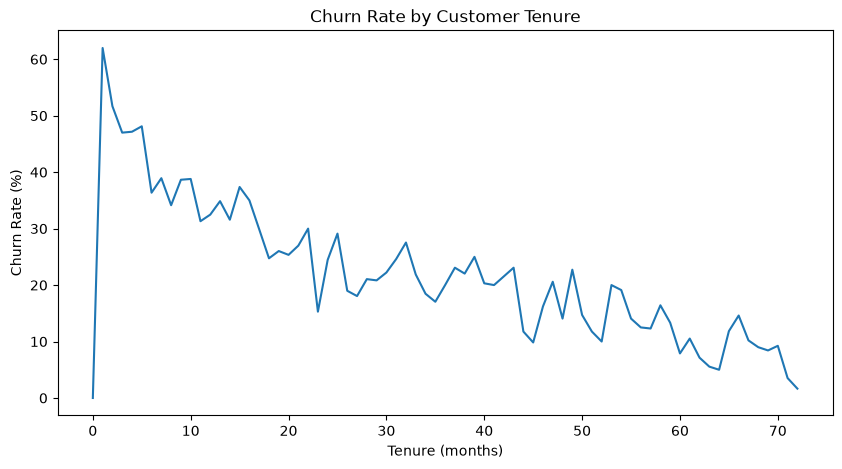

In [33]:
tenure_churn = (
    pd.crosstab(
        df["tenure"],
        df["Churn"],
        normalize="index"
    ) * 100
)

tenure_churn["Yes"].plot(
    kind="line",
    figsize=(10, 5)
)

plt.xlabel("Tenure (months)")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Customer Tenure")
plt.show()

In [34]:
df["MonthlyCharges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

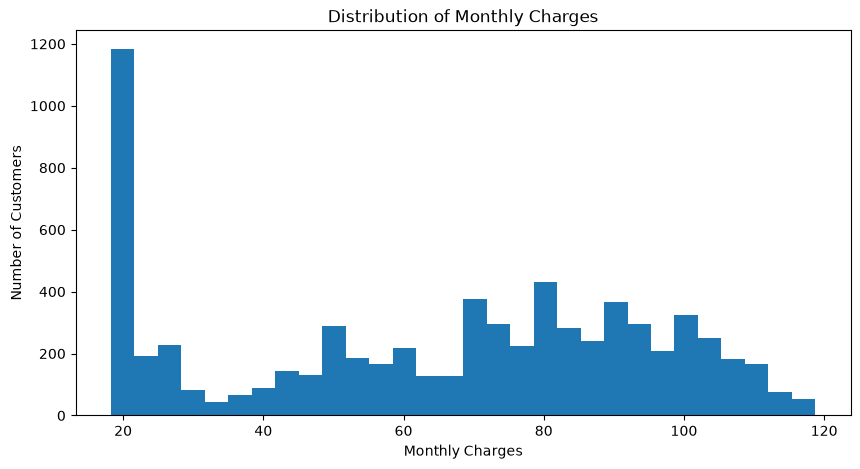

In [35]:
df["MonthlyCharges"].plot(
    kind="hist",
    bins=30,
    figsize=(10, 5)
)

plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.title("Distribution of Monthly Charges")
plt.show()

In [36]:
df["MonthlyChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 30, 60, 90, 120],
    labels=["0-30", "30-60", "60-90", "90-120"]
)

In [37]:
pd.crosstab(
    df["MonthlyChargesGroup"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
MonthlyChargesGroup,,
0-30,90.199637,9.800363
30-60,74.071146,25.928854
60-90,66.093881,33.906119
90-120,67.222542,32.777458


In [38]:
pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


In [39]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [40]:
pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


In [41]:
pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


In [42]:
pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


In [43]:
pd.crosstab(
    df["OnlineSecurity"],
    df["TechSupport"],
    normalize="index"
) * 100

TechSupport,No,No internet service,Yes
OnlineSecurity,,,
No,72.984563,0.0,27.015437
No internet service,0.000000,100.0,0.000000
Yes,45.567112,0.0,54.432888


In [44]:
df[["SeniorCitizen", "tenure", "MonthlyCharges"]].corr()

,SeniorCitizen,tenure,MonthlyCharges
SeniorCitizen,1.000000,0.016567,0.220173
tenure,0.016567,1.000000,0.247900
MonthlyCharges,0.220173,0.247900,1.000000


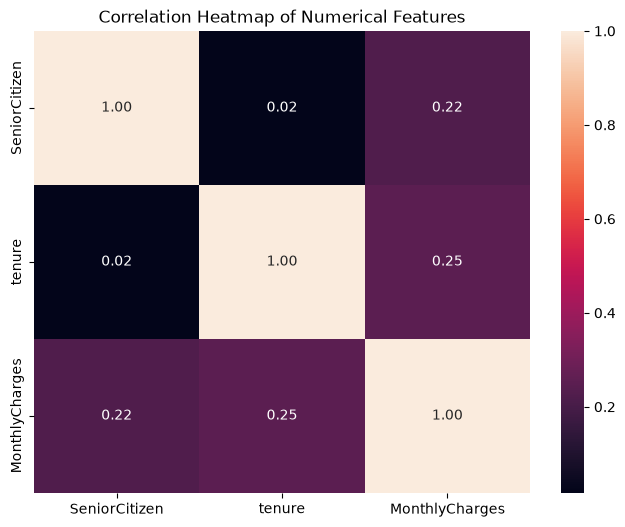

In [45]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[["SeniorCitizen", "tenure", "MonthlyCharges"]].corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [46]:
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

In [47]:
df["TotalCharges"].tail(10)

7033    2625.25
7034    6886.25
7035     1495.1
7036      743.3
7037     1419.4
7038     1990.5
7039     7362.9
7040     346.45
7041      306.6
7042     6844.5
Name: TotalCharges, dtype: str

In [49]:
eda_df = df.copy()

In [50]:
eda_df["TotalCharges"] = pd.to_numeric(
    eda_df["TotalCharges"],
    errors="coerce"
)

In [51]:
eda_df["TotalCharges"].isna().sum()

np.int64(11)

In [52]:
eda_df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [53]:
eda_df[["tenure", "MonthlyCharges", "TotalCharges"]].corr()

,tenure,MonthlyCharges,TotalCharges
tenure,1.00000,0.247900,0.825880
MonthlyCharges,0.24790,1.000000,0.651065
TotalCharges,0.82588,0.651065,1.000000


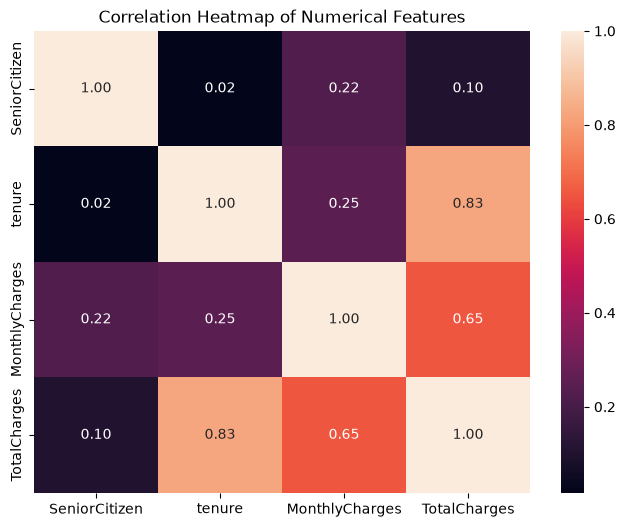

In [54]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    eda_df[
        ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
    ].corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [55]:
eda_df.groupby("Churn")["TotalCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.0,2555.344141,2329.456984,18.80,577.825,1683.60,4264.125,8672.45
Yes,1869.0,1531.796094,1890.822994,18.85,134.500,703.55,2331.300,8684.80


In [57]:
pd.crosstab(
    [df["Contract"], df["InternetService"]],
    df["Churn"],
    normalize="index"
) * 100

Churn                                  No        Yes
Contract       InternetService                      
Month-to-month DSL              67.784137  32.215863
               Fiber optic      45.394737  54.605263
               No               81.106870  18.893130
One year       DSL              90.701754   9.298246
               Fiber optic      80.705009  19.294991
               No               97.527473   2.472527
Two year       DSL              98.089172   1.910828
               Fiber optic      92.773893   7.226107
               No               99.216301   0.783699

In [58]:
contract_internet_churn = (
    pd.crosstab(
        [df["Contract"], df["InternetService"]],
        df["Churn"],
        normalize="index"
    ) * 100
)

In [59]:
contract_internet_churn

Churn                                  No        Yes
Contract       InternetService                      
Month-to-month DSL              67.784137  32.215863
               Fiber optic      45.394737  54.605263
               No               81.106870  18.893130
One year       DSL              90.701754   9.298246
               Fiber optic      80.705009  19.294991
               No               97.527473   2.472527
Two year       DSL              98.089172   1.910828
               Fiber optic      92.773893   7.226107
               No               99.216301   0.783699

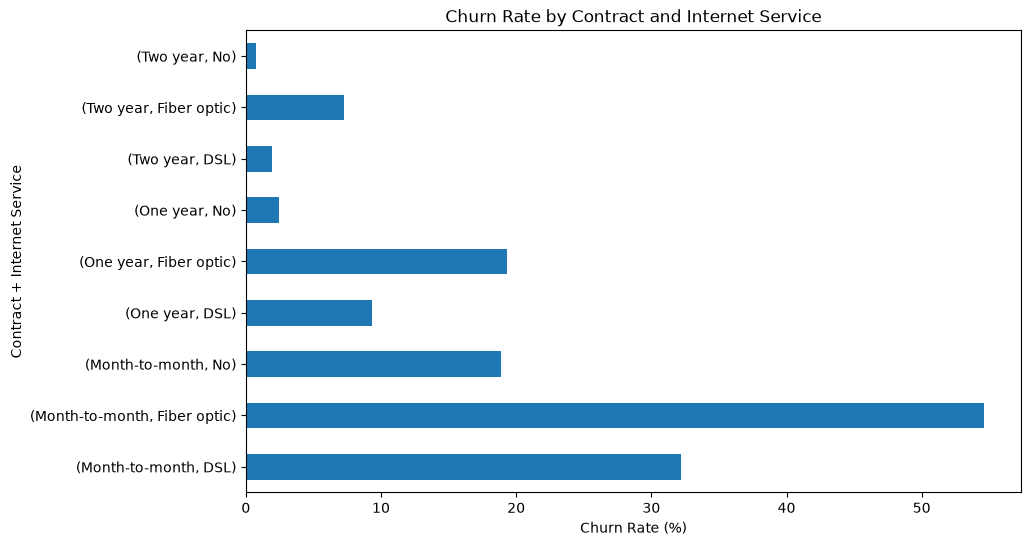

In [60]:
contract_internet_churn["Yes"].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("Churn Rate (%)")
plt.ylabel("Contract + Internet Service")
plt.title("Churn Rate by Contract and Internet Service")
plt.show()

In [61]:
pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


In [62]:
pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


# Exploratory Data Analysis — Findings and Conclusions

## 1. Dataset Overview

The Telco Customer Churn dataset contains **7,043 customers** and **21 columns**.

The target variable is `Churn`, which indicates whether a customer left the company:

* `No` — Customer stayed
* `Yes` — Customer churned

The `customerID` column is a unique identifier for each customer and does not contain meaningful predictive information. It will therefore be excluded from the modeling features.

---

## 2. Target Distribution

The target variable is moderately imbalanced:

| Churn | Customers | Percentage |
| ----- | --------: | ---------: |
| No    |     5,174 |     73.46% |
| Yes   |     1,869 |     26.54% |

Because the majority class represents approximately 73% of the dataset, accuracy alone will not be sufficient for evaluating the model.

The following metrics will therefore be considered:

* Precision
* Recall
* F1-score
* ROC-AUC
* PR-AUC
* Accuracy as a secondary metric

The final classification threshold will also be selected based on the business objective rather than automatically assuming a threshold of 0.50.

---

## 3. Missing Values and Data Quality

The `TotalCharges` column is stored as an `object` data type even though it contains numeric-looking values.

There are **11 blank values** in this column and no actual `NaN` values in the raw dataset.

All 11 customers with blank `TotalCharges` have `tenure = 0`.

This suggests that these values represent newly acquired customers who have not accumulated total charges yet, rather than random missing data.

During preprocessing, `TotalCharges` will therefore be:

1. Converted from string to numeric.
2. Blank strings converted to missing values.
3. Missing values handled appropriately based on the data meaning.

The raw dataset will not be modified during EDA.

---

## 4. Duplicate Analysis

No duplicate rows were found in the dataset.

The `customerID` column contains **7,043 unique values**, matching the total number of records.

Therefore, there is no evidence of duplicated customer records.

---

## 5. Tenure and Churn

Customer tenure ranges from **0 to 72 months**.

* Mean tenure: **32.37 months**
* Median tenure: **29 months**
* Minimum: **0 months**
* Maximum: **72 months**

A strong pattern was observed between tenure and churn.

Customers with shorter tenure generally have substantially higher churn rates. For example:

* 1 month: approximately **62% churn**
* 2 months: approximately **52% churn**
* 3 months: approximately **47% churn**
* 72 months: approximately **1.7% churn**

The 0-month group has 0% observed churn, but this group contains only 11 customers and should not be generalized.

**Conclusion:** `tenure` is an important candidate feature for the prediction model.

---

## 6. Monthly Charges and Churn

`MonthlyCharges` ranges from **18.25 to 118.75**.

* Mean: **64.76**
* Median: **70.35**

An overall association between higher monthly charges and churn was observed.

| Monthly Charges | Churn Rate |
| --------------- | ---------: |
| 0–30            |      9.80% |
| 30–60           |     25.93% |
| 60–90           |     33.91% |
| 90–120          |     32.78% |

Customers in the higher monthly-charge ranges generally show higher churn rates.

However, the relationship is not perfectly monotonic, so this should be treated as an association rather than a causal relationship.

**Conclusion:** `MonthlyCharges` is a useful candidate feature.

The temporary `MonthlyChargesGroup` variable was created only for EDA and will not automatically be included as a production feature.

---

## 7. Total Charges and Churn

After temporarily converting `TotalCharges` to numeric values for EDA, the following pattern was observed:

* Mean `TotalCharges` for customers who stayed: **2555.34**
* Mean `TotalCharges` for customers who churned: **1531.80**
* Median for customers who stayed: **1683.60**
* Median for customers who churned: **703.55**

Churned customers generally have lower total charges.

However, `TotalCharges` has a strong positive correlation with `tenure` (**0.826**). Since customers with shorter tenure are also more likely to churn, lower total charges may partly reflect shorter customer tenure.

Therefore, low `TotalCharges` should not be interpreted as a direct cause of churn.

**Conclusion:** `TotalCharges` will remain a candidate feature, and its incremental predictive value will be evaluated during modeling.

---

## 8. Contract and Churn

Contract type showed one of the strongest associations with churn:

| Contract       | Churn Rate |
| -------------- | ---------: |
| Month-to-month | **42.71%** |
| One year       |     11.27% |
| Two year       |      2.83% |

Customers with month-to-month contracts have substantially higher observed churn than customers with longer-term contracts.

**Conclusion:** `Contract` is an important candidate feature.

This relationship represents an association in the dataset and should not be interpreted as proof that contract type directly causes churn.

---

## 9. Payment Method and Churn

A substantial difference was observed across payment methods:

| Payment Method            | Churn Rate |
| ------------------------- | ---------: |
| Electronic check          | **45.29%** |
| Mailed check              |     19.11% |
| Bank transfer (automatic) |     16.71% |
| Credit card (automatic)   |     15.24% |

Customers using electronic checks have a considerably higher observed churn rate.

**Conclusion:** `PaymentMethod` is an important candidate feature.

The relationship may also be influenced by other variables such as contract type, tenure, and service configuration.

---

## 10. Internet Service and Churn

A strong association was observed between internet service type and churn:

| Internet Service    | Churn Rate |
| ------------------- | ---------: |
| Fiber optic         | **41.89%** |
| DSL                 |     18.96% |
| No internet service |      7.40% |

Fiber-optic customers have a substantially higher observed churn rate than DSL and customers without internet service.

**Conclusion:** `InternetService` is an important candidate feature.

This does not imply that fiber-optic service itself causes churn.

---

## 11. Technical Support and Churn

Customers without technical support showed substantially higher churn:

| TechSupport         | Churn Rate |
| ------------------- | ---------: |
| No                  | **41.64%** |
| Yes                 |     15.17% |
| No internet service |      7.40% |

**Conclusion:** `TechSupport` is a strong candidate feature.

---

## 12. Online Security and Churn

A similar pattern was observed for online security:

| OnlineSecurity      | Churn Rate |
| ------------------- | ---------: |
| No                  | **41.77%** |
| Yes                 |     14.61% |
| No internet service |      7.40% |

`OnlineSecurity` and `TechSupport` also showed a relationship with each other, indicating that some service-related features may contain overlapping information.

**Conclusion:** `OnlineSecurity` will remain a candidate feature and will be evaluated together with other service-related variables.

---

## 13. Senior Citizen and Churn

The observed churn rate differs substantially by senior-citizen status:

| SeniorCitizen | Churn Rate |
| ------------- | ---------: |
| No            |     23.61% |
| Yes           | **41.68%** |

Senior customers have a higher observed churn rate in this dataset.

**Conclusion:** `SeniorCitizen` is a useful candidate feature.

---

## 14. Partner and Churn

Customers without a partner showed a higher churn rate:

| Partner | Churn Rate |
| ------- | ---------: |
| No      | **32.96%** |
| Yes     |     19.66% |

**Conclusion:** `Partner` is a useful candidate feature.

---

## 15. Dependents and Churn

A similar pattern was observed for dependents:

| Dependents | Churn Rate |
| ---------- | ---------: |
| No         | **31.28%** |
| Yes        |     15.45% |

Customers without dependents have a substantially higher observed churn rate.

**Conclusion:** `Dependents` is a useful candidate feature.

---

## 16. Numerical Correlation Analysis

The main numerical correlations were:

| Variables                     | Correlation |
| ----------------------------- | ----------: |
| Tenure ↔ TotalCharges         |   **0.826** |
| MonthlyCharges ↔ TotalCharges |   **0.651** |
| Tenure ↔ MonthlyCharges       |       0.248 |
| SeniorCitizen ↔ Tenure        |       0.017 |

The strongest relationship is between `tenure` and `TotalCharges`.

This does not automatically mean that one feature should be removed. The final decision will be based on model experiments and predictive performance.

---

## 17. Important Feature Interaction

An important interaction was discovered between `Contract` and `InternetService`.

| Contract + Internet Service  | Churn Rate |
| ---------------------------- | ---------: |
| Month-to-month + Fiber optic | **54.61%** |
| Month-to-month + DSL         |     32.22% |
| Month-to-month + No internet |     18.89% |
| One year + Fiber optic       |     19.29% |
| Two year + Fiber optic       |      7.23% |

The churn rate for fiber-optic customers changes substantially depending on contract type.

The combination of **month-to-month contract + fiber optic service** has particularly high observed churn.

This suggests that interactions between customer characteristics may be useful for prediction.

---

# Overall EDA Conclusions

The main patterns identified during EDA are:

1. Churn is moderately imbalanced, with approximately **26.5%** positive cases.
2. Short-tenure customers show substantially higher churn.
3. Month-to-month customers have much higher churn than customers with longer contracts.
4. Fiber-optic customers show higher observed churn.
5. Electronic-check customers show particularly high churn.
6. Customers without technical support or online security show higher churn.
7. Senior customers have higher observed churn.
8. Customers without partners or dependents show higher observed churn.
9. Higher monthly charges are generally associated with higher churn.
10. `TotalCharges` is strongly related to `tenure`.
11. The combination of contract type and internet service reveals an important interaction.
12. Values such as `No internet service` and `No phone service` represent meaningful customer states and should **not** be blindly treated as missing values.

These findings represent **associations observed in the dataset, not causal relationships**.

The purpose of EDA was to understand the data and identify preprocessing and modeling considerations. These findings will guide the next stage of the project.

---

# Preprocessing Decisions Derived from EDA

Based on the EDA, the preprocessing stage will need to address:

* Remove `customerID` from the predictive features.
* Convert `TotalCharges` from string to numeric.
* Handle the 11 missing `TotalCharges` values appropriately.
* Encode categorical variables.
* Convert the target `Churn` into a binary representation.
* Preserve meaningful categorical states such as `No internet service` and `No phone service`.
* Separate the data into training, validation, and test sets.
* Build preprocessing using reusable pipeline components rather than performing transformations manually only in the notebook.
* Prevent data leakage by fitting preprocessing transformations only on the training data.
